# Data Preprocessing

This notebook is dedicated towards examining the data.

# Packages and paths

In [34]:
import os
import numpy as np
import pandas as pd
import datetime as dt

import matplotlib.pyplot as plt
from   matplotlib.patches import Patch

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
data_path = os.path.join(repo_path, "data", "DataBase")

In [113]:
path    = os.path.join(repo_path, "data", "EquityForecastTickerGuide.xlsx")
RENAMER = (pd
    .read_excel(io = path, sheet_name = "Renamer")
    .loc[lambda x: x.group == "renamer"]
    .set_index("old_name")
    .new_name
    .to_dict())

FLOAT_FORMAT = "{:.2f}".format

# Analyzing Fundamental Data

The dataset consists of index-level fundamental factors sourced from Bloomberg. Although these metrics are reported quarterly, their values evolve throughout each quarter as constituent companies release financial results at different times. To capture this reporting dynamic, several quarterly aggregation methods were constructed, including the first observation, last observation, mean, median, mode, minimum, and maximum observed within each quarter.

In [3]:
sample_tickers = ['SPX Index', 'RTY Index', 'NDX Index']
start_date     = dt.date(year = 2024, month = 1, day = 1)

path   = os.path.join(data_path, "RawData", "RawEquityIndexData.parquet")
df_raw = pd.read_parquet(path = path, engine = "pyarrow")

In [4]:
df_longer = (df_raw
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .loc[lambda x: x.field == "IS_EPS"]
    [["date", "ticker", "value"]]
    .drop_duplicates()
    .assign(date = lambda x: pd.to_datetime(x.date).dt.date)
    .loc[lambda x: x.date >= start_date])

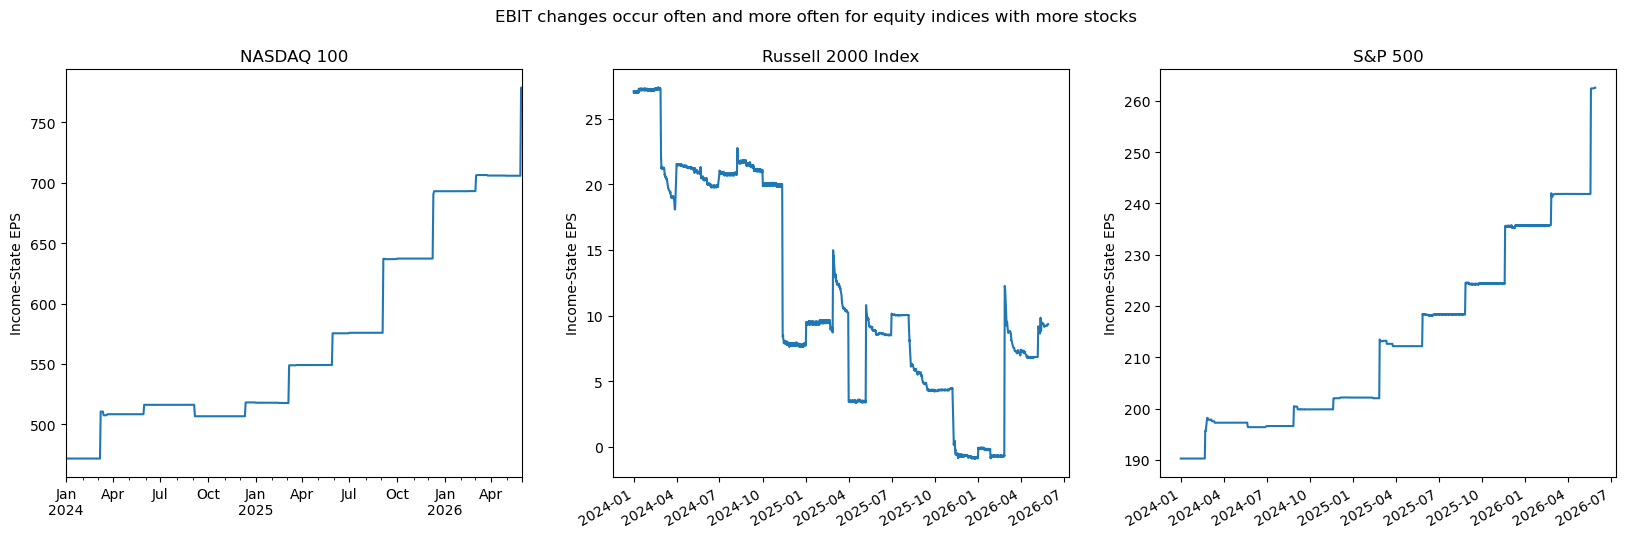

In [5]:
tickers   = df_longer.ticker.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(tickers), figsize = (20,6))

security_mapper = {
    "RTY": "Russell 2000 Index",
    "SPX": "S&P 500",
    "NDX": "NASDAQ 100"}

for ticker, ax in zip(tickers, axes.flatten()): 

    (df_longer
        .loc[lambda x: x.ticker == ticker]
        .assign(date = lambda x: pd.to_datetime(x.date))
        .set_index("date")
        .sort_index()
        [["value"]]
        .plot(
            ax     = ax,
            ylabel = "Income-State EPS",
            legend = False,
            xlabel = "",
            title  = security_mapper[ticker.split(" ")[0]]))

fig.suptitle("EBIT changes occur often and more often for equity indices with more stocks")
plt.show()

Now examine the quarterly data which which is just the values resampled quarterly for various statistics. 

In [6]:
date_path   = os.path.join(data_path, "DailyData", "DailyEstimateEquityIndexData.parquet")
df_date_map = (pd
    .read_parquet(path = date_path, engine = "pyarrow")
    [["date"]]
    .groupby("date")
    .head(1)
    .assign(quarter = lambda x: x.date.dt.year.astype(str) + "-Q" + x.date.dt.quarter.astype("str")))

In [7]:
path         = os.path.join(data_path, "Quarterlyized", "QuarterlyFundamentalEquityIndexData.parquet")
df_quarterly = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .loc[lambda x: x.field == "IS_EPS"]
    .assign(year = lambda x: x.quarter.str.split("-").str[0].astype(int))
    .loc[lambda x: x.year >= 2020]
    .merge(right = df_date_map, how = "inner", on = ["quarter"]))

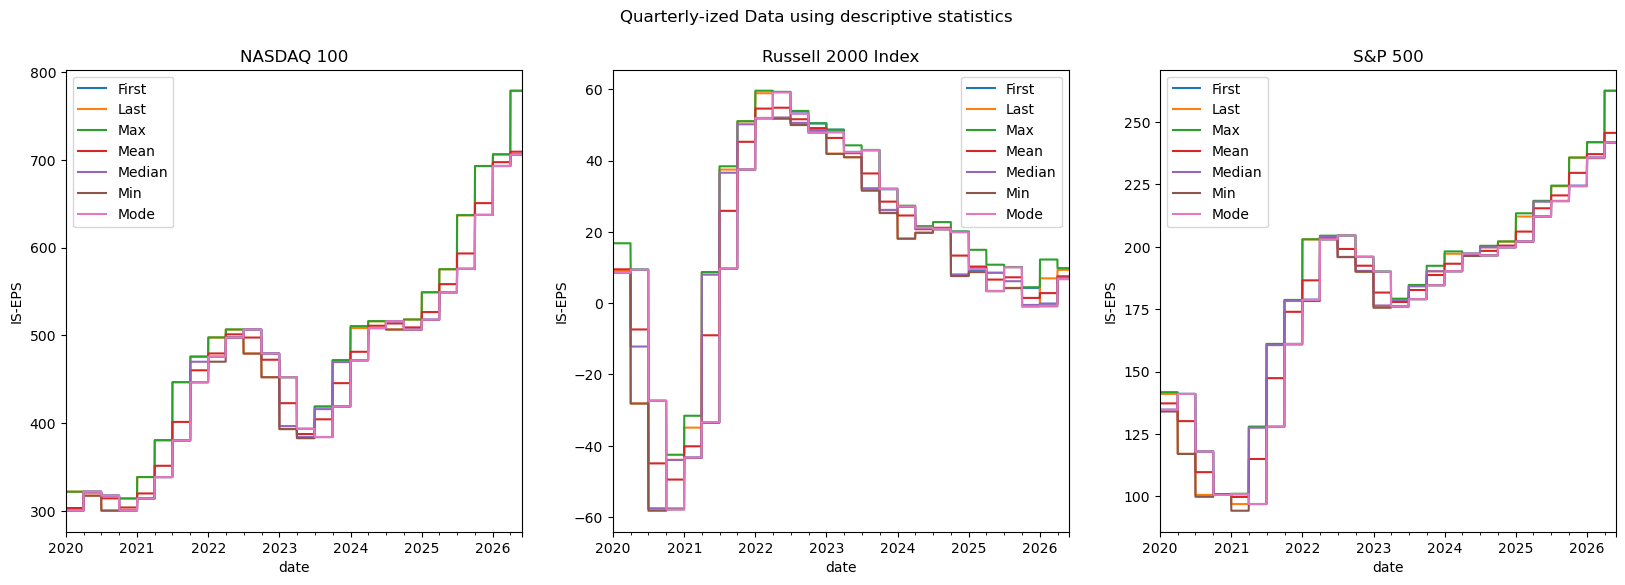

In [8]:
tickers   = df_quarterly.ticker.drop_duplicates().to_list()
fig, axes = plt.subplots(ncols = len(tickers), figsize = (20,6))

for ticker, ax in zip(tickers, axes.flatten()): 

    (df_quarterly
        .loc[lambda x: x.ticker == ticker]
        .assign(stat_method = lambda x: x.stat_method.str.capitalize())
        .rename(columns = {"stat_method": ""})
        .pivot(index = "date", columns = "", values = "value")
        .plot(
            ax     = ax,
            ylabel = "IS-EPS",
            title  = security_mapper[ticker.split(" ")[0]]))

fig.suptitle("Quarterly-ized Data using descriptive statistics")
plt.show()

# Analyzing the Estimated data

The estimated data is done through the Bloomberg Estimate which likely aggregates individual estimates and is subject to the same variation as above. 

In [9]:
path    = os.path.join(data_path, "DailyData", "DailyEstimateEquityIndexData.parquet")
df_best = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.field == "BEST_EPS"]
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .assign(
        security = lambda x: x.ticker.str.split(" ").str[0],
        year     = lambda x: x.date.dt.year))

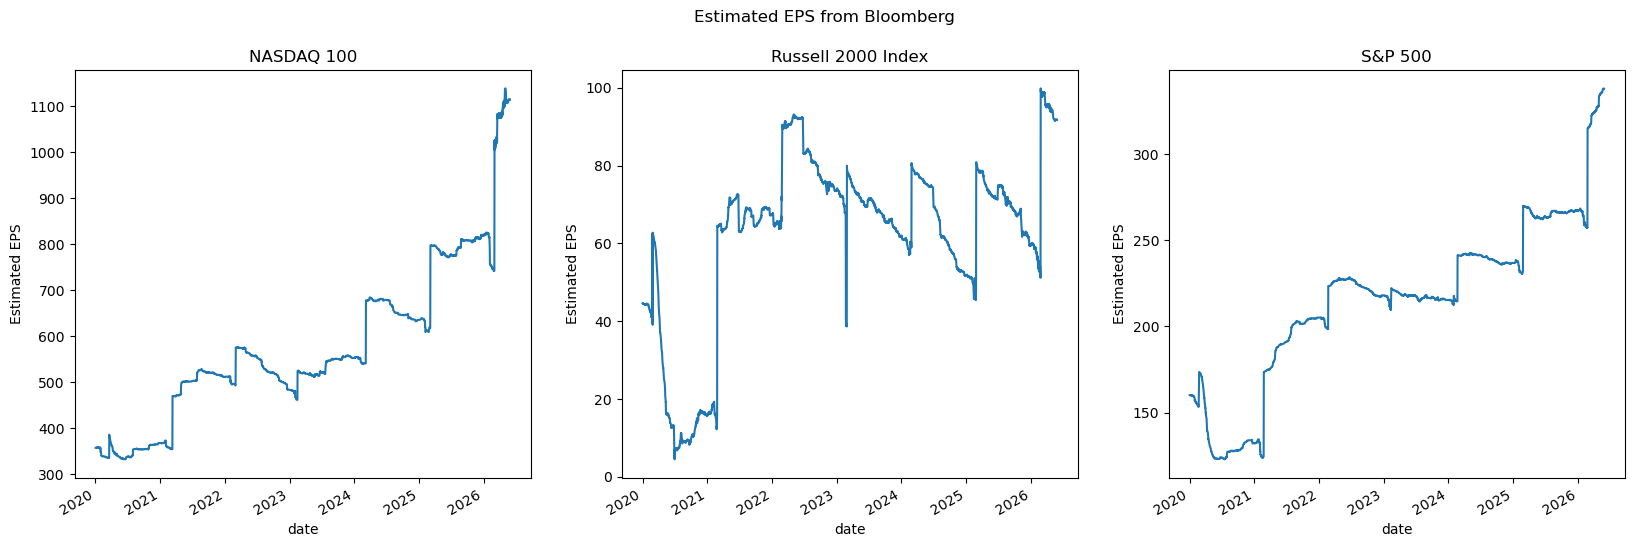

In [10]:
tickers   = df_best.security.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(tickers), figsize = (20,6))

for ticker, ax in zip(tickers, axes.flatten()): 

    (df_best.loc[
        lambda x: x.security == ticker].
        loc[lambda x: x.year >= 2020].
        set_index("date")
        [["value"]].
        sort_index().
        plot(
            ax     = ax,
            legend = False,
            ylabel = "Estimated EPS",
            title  = security_mapper[ticker]))

fig.suptitle("Estimated EPS from Bloomberg")
plt.show()

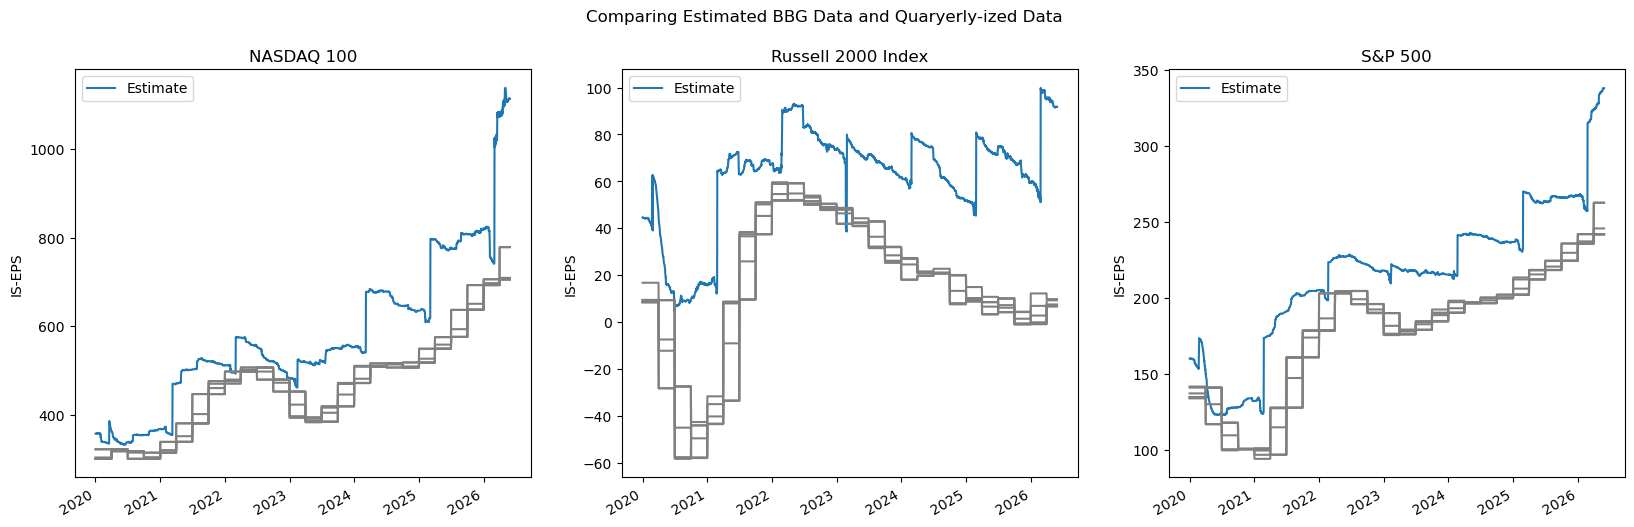

In [11]:
fig, axes = plt.subplots(ncols = len(tickers), figsize = (20,6))

for ticker, ax in zip(tickers, axes.flatten()):

    df_estimate = (df_best
        .assign(year = lambda x: x.date.dt.year)
        .loc[lambda x: x.year >= 2020]
        .loc[lambda x: x.field == "BEST_EPS"]
        .loc[lambda x: x.security == ticker]
        [["date", "value"]]
        .rename(columns = {"value": "Estimate"})
        .set_index("date")
        .sort_index()
        .plot(ax = ax))

    tmp_ticker = ticker + " Index"
    
    (df_quarterly
        .loc[lambda x: x.ticker == tmp_ticker]
        .pivot(index = "date", columns = "stat_method", values = "value")
        .plot(
            ax     = ax,
            color  = "grey",
            legend = False,
            title  = security_mapper[ticker],
            ylabel = "IS-EPS",
            xlabel = ""))

fig.suptitle("Comparing Estimated BBG Data and Quaryerly-ized Data")
plt.show()

In [96]:
path = os.path.join(data_path, "Quarterlyized", "QuarterlyFundamentalEquityIndexData.parquet")

df_quarterly_all = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .assign(year = lambda x: x.quarter.str.split("-").str[0].astype(int)))

In [117]:
def _get_cross_correlation(df: pd.DataFrame) -> pd.DataFrame:

    mean_val = (df
        .diff()
        .corr()
        .pipe(lambda x: x.where(~np.eye(len(x), dtype = bool)))
        .stack()
        .mean())

    return mean_val
    

display(df_quarterly_all
    [["quarter", "ticker", "field", "stat_method", "value"]]
    .pivot(index = ["quarter", "ticker", "field"], columns = "stat_method", values = "value")
    .reset_index()
    .set_index("quarter")
    .groupby(["ticker", "field"])
    .apply(_get_cross_correlation)
    .to_frame(name = "avg_corr")
    .reset_index()
    .replace(RENAMER)
    .assign(ticker = lambda x: x.ticker.str.split(" ").str[0])
    .rename(columns = {
        "ticker": "Ticker",
        "field" : "Field"})
    .pivot(index = "Field", columns = "Ticker", values = "avg_corr"))

Ticker,NDX,RTY,SPX
Field,,,
Cur EV,0.676729,0.504365,0.642051
Cur EV/12M EBITDA,0.605843,0.712307,0.442809
EBIT,0.821934,0.278010,0.321142
EBITDA,0.756018,0.996698,0.660819
EV/12M EBITDA,0.439545,0.700821,0.418356
FCF,0.778040,0.181439,0.686079
Gross Margin,0.697338,0.398387,0.352695
IS-EPS,0.752781,0.200510,0.421798


# Determining the Data Universe with respect to train/test/split

Since we are trying to make cross-sectional models we need to pick a universe reasonable universe but also account for the out-of-sample size. 

In [118]:
quarter_path = os.path.join(data_path, "DailyData", "DailyFundamentalEquityIndexData.parquet")
fields       = (pd.read_parquet(
    path = quarter_path, engine = "pyarrow").
    field.
    drop_duplicates().
    to_list())

In [119]:
path    = os.path.join(data_path, "DailyData", "DailyFundamentalEquityIndexData.parquet")
df_date = (pd
    .read_parquet(path = path, engine = "pyarrow")
    [["date", "ticker", "field"]].
    groupby(["ticker", "field"]).
    agg("min").
    reset_index().
    drop(columns = ["field"]).
    groupby("ticker").
    agg("max").
    sort_values("date"))

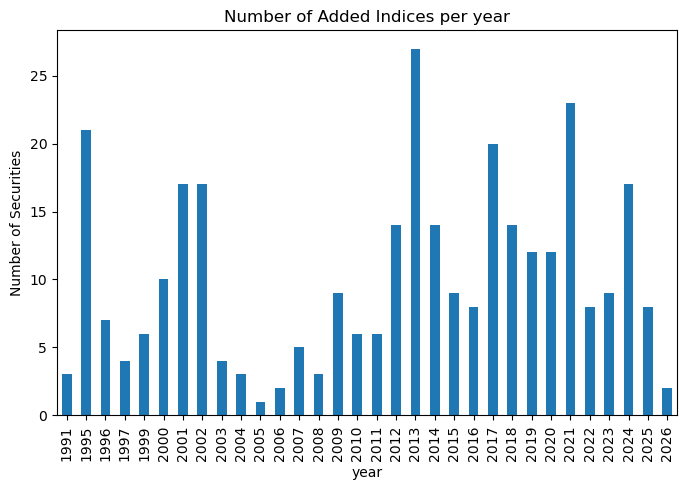

In [120]:
(df_date.assign(
    year = lambda x: x.date.dt.year).
    drop(columns = ["date"]).
    reset_index().
    groupby("year").
    agg("count").
    plot(
        figsize = (8,5),
        kind    = "bar",
        title   = "Number of Added Indices per year",
        legend  = False,
        ylabel  = "Number of Securities"))

plt.show()

We'll use 2017 as the cutoff year and set the universe resriction to having data in 2015 to assure it has some history. We'll use whatever history the data has regardless of size since that is how it would be done in real life. 

For now, with ease of use when it comes to coding and modelling we'll use SPX, RTY, and NDX as our starting cases. Then as the code base develops we'll expand into more indices.  